In [ ]:
# Run from the workshop root (workshops/w2): src/, artifacts/ and export-* are resolved relative to it.
import os
from pathlib import Path
_here = Path.cwd().resolve()
W2_ROOT = next(p for p in (_here, *_here.parents) if p.name == "w2" and (p / "src").is_dir())
os.chdir(W2_ROOT)
print("cwd:", Path.cwd())

# w2 · LSTM vs GRU for behaviour trajectories (PyTorch)

`w2_neural_models.ipynb` classifies churn from the 90-day sequence. This notebook uses the **same tensor, split and scalers** for a different task: predicting how each user will behave over the **next 7 days**. The goal is a behaviour simulator that the retention agents of `wfinal` can query.

The 90-day window is split in two:

```text
day:   0 ............................. 82 | 83 ........ 89
       input (83 days, 14 channels)       | target (7 days, 11 event targets)
```

| Cohort | Input | Target |
|---|---|---|
| `train_feb` | 2016-11-03 to 2017-01-24 | 2017-01-25 to 2017-01-31 |
| `test` (March) | 2016-12-01 to 2017-02-21 | 2017-02-22 to 2017-02-28 |

The days are "future" relative to what the model sees, not to the calendar, so the export does not need to be rebuilt.

**Option B.** The network predicts only the **events** (listening and payments). The 7 subscription-state channels are not predicted. Rebuilding them from the events to simulate whole weeks (`simulate.py`) is not part of this version; this notebook trains the models and evaluates the predicted events.

**Population.** Same run as the classifiers: by default the **manual segment** with the calendar cutoff (`W2_ALIGNMENT=calendar`, set in the first code cell). The split and the scalers are those of `artifacts/sherlock_w2_v6_manual/feature_preparation`, written by `w2_neural_models_manual.ipynb`.

The two recurrent cells are compared under identical conditions: same input, head, loss, search space, budget and evaluation.

## 1. Configuration

Settings live in `src/models/trajectory_models/config.py`. Artifacts are written to `artifacts/<run>_traj/` (here `artifacts/sherlock_w2_v6_manual_traj/`), so the classifier artifacts are not touched.

- `N_TRIALS=10` per model, `EPOCHS=40`, `PATIENCE=5`, `BATCH_SIZE=512`: same procedure as the classifier, with twice the search budget because the task is new.
- `HIDDEN_DIMS=(64, 128, 256)`: wider than the classifier, since the head now emits 7 × 11 = 77 values instead of 1.

In [1]:
import torch; torch.cuda.is_available()

True

In [2]:
from pathlib import Path
import json
import os

# Run selection, read by src.models at import time (same switches as the classifiers).
os.environ["W2_ALIGNMENT"] = "calendar"
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display

warnings.filterwarnings("ignore")

# src.models reads the run selection once, at import time: a kernel that imported
# older code or another selection must be restarted.
import sys
_loaded = sys.modules.get("src.models.constants")
if _loaded is not None and (getattr(_loaded, "DATASET_VERSION", None) != 6
                            or _loaded.ALIGNMENT != os.environ.get("W2_ALIGNMENT", "calendar")):
    raise RuntimeError("This kernel holds an old src.models (or another run selection). "
                       "Restart the kernel and run the notebook from the top.")

from src.models.trajectory_models.config import (
    BATCH_SIZE,
    COMPARISON_DIR,
    EPOCHS,
    EXPORT_DIR,
    FEATURE_DIR,
    HIDDEN_DIMS,
    HORIZON,
    INPUT_DAYS,
    LAYER_DIM_RANGE,
    LR_RANGE,
    N_TARGETS,
    N_TRIALS,
    PATIENCE,
    SEED,
    TARGET_NAMES,
    WEIGHT_DECAY_RANGE,
    model_dirs,
)
from src.models.trajectory_models.model import MODELS
from src.models.trajectory_models.train import resolve_device

DEVICE = resolve_device()

settings = pd.DataFrame(
    [
        ("models", ", ".join(name.upper() for name in MODELS)),
        ("export_dir", str(EXPORT_DIR)),
        ("feature_dir", str(FEATURE_DIR)),
        ("comparison_dir", str(COMPARISON_DIR)),
        ("device", str(DEVICE)),
        ("seed", SEED),
        ("input_days", INPUT_DAYS),
        ("horizon", HORIZON),
        ("n_targets", N_TARGETS),
        ("n_trials", N_TRIALS),
        ("epochs", EPOCHS),
        ("patience", PATIENCE),
        ("batch_size", BATCH_SIZE),
        ("hidden_dims", HIDDEN_DIMS),
        ("layer_dim_range", LAYER_DIM_RANGE),
        ("lr_range", LR_RANGE),
        ("weight_decay_range", WEIGHT_DECAY_RANGE),
    ],
    columns=["setting", "value"],
)
display(settings)
pd.DataFrame({name.upper(): {k: str(v) for k, v in model_dirs(name).items()} for name in MODELS})

,setting,value
0,models,"LSTM, GRU"
1,export_dir,export-sequential-v6-manual
2,feature_dir,artifacts/sherlock_w2_v6_manual/feature_prepar...
3,comparison_dir,artifacts/sherlock_w2_v6_manual_traj/comparison
4,device,cuda
5,seed,110
6,input_days,83
7,horizon,7
8,n_targets,11
9,n_trials,10


,LSTM,GRU
artifacts,artifacts/sherlock_w2_v6_manual_traj/lstm,artifacts/sherlock_w2_v6_manual_traj/gru
optuna,artifacts/sherlock_w2_v6_manual_traj/lstm/optuna,artifacts/sherlock_w2_v6_manual_traj/gru/optuna
checkpoints,artifacts/sherlock_w2_v6_manual_traj/lstm/chec...,artifacts/sherlock_w2_v6_manual_traj/gru/check...
evaluation,artifacts/sherlock_w2_v6_manual_traj/lstm/eval...,artifacts/sherlock_w2_v6_manual_traj/gru/evalu...


## 2. Data

### 2.1 Same export, same split, same scalers

`load_trajectory_data` loads the artifacts of the classifier (`load_prepared_data`) and only changes what each batch contains. **Run `w2_neural_models_manual.ipynb` first**: it writes that preparation (`prepare()`) from `export-sequential-v6-manual`; `load_prepared_data` stops with an error if the preparation does not match the export. The tensor is held in RAM and scaled once per phase, as in the classifier. The split (`fit` / `stop` / `tune` from February, `test` = March, `development` = all of February) and the scalers fitted per phase are reused unchanged.

**Channels: 14.** The export holds exactly the channels the networks read: the 8 listening channels, 3 payment events and 3 payment states. The other six channels computed by the builder (cancel / auto-renew counters and flags, `tx_expiry_known`, `tx_state_ambiguous`) are almost constant in the manual segment and are not exported (`w2_sequence_preprocessing.ipynb`, section 7).

In [3]:
from src.models.trajectory_models.data import load_trajectory_data

data = load_trajectory_data(feature_dir=FEATURE_DIR, export_dir=EXPORT_DIR)

print("tensor:", data.view.shape, data.view.dtype)
print("input_dim:", data.input_dim)
pd.DataFrame(
    [{"part": part, "n_users": len(data.rows(part))}
     for part in ("fit", "stop", "tune", "test", "development")]
)

train_feb rows:   111,751 | label month: 2017-02 | churn rate: 0.3215
test      rows:   113,870 | label month: 2017-03 | churn rate: 0.4110
labelled cohorts: (225621, 4) | users in both months: 60478
sequence data: 225,621 rows | RAM cache on (needs 1.1 GB, limit 8 GB)
tensor: (225621, 90, 14) float16
input_dim: 14


,part,n_users
0,fit,83814
1,stop,13969
2,tune,13968
3,test,113870
4,development,111751


### 2.2 Targets

Each batch is `x` of shape `(B, 83, 14)` (scaled days 0..82 of the 14 model channels) and `y` of shape `(B, 7, 11)` (days 83..89):

| Positions | Target | Type | Defined on |
|---|---|---|---|
| 0–6 | `num_25` … `total_secs` | scaled amount | active days |
| 7 | `active` | 0/1 | every day |
| 8 | `pay` (`tx_count > 0`) | 0/1 | every day |
| 9–10 | `tx_paid_sum`, `tx_plan_days_sum` | scaled amount | payment days |

Every target comes from one of the 14 channels the model also reads: the listening events and the payment events. The 3 payment-state channels are not predicted; they follow from the payments.

Binary targets are read from the **raw** tensor: after standard scaling, a raw `tx_count` of 1 becomes about −0.1, not 1.

Listening is split in two parts ("hurdle"): *does the user listen?* and *how much, if they do?*. After scaling, an inactive day and an average active day are both 0, so a single regression over all days would learn the average of the two and produce users who listen a little every day, which never happens.

In [4]:
xb, yb = next(iter(data.iter_batches(data.rows("fit")[:BATCH_SIZE], "fit", BATCH_SIZE)))
print("x:", tuple(xb.shape), "| y:", tuple(yb.shape))

y_np = yb.numpy()
pd.DataFrame(
    {
        "target": TARGET_NAMES,
        "mean (batch)": y_np.reshape(-1, N_TARGETS).mean(axis=0).round(4),
    }
).set_index("target").T

loaded raw tensor into RAM: (225621, 90, 14) float16 in 0.3s
scaled tensor for phase 'fit' cached in 5.2s
x: (512, 83, 14) | y: (512, 7, 11)


target,num_25,num_50,num_75,num_985,num_100,num_unq,total_secs,active,pay,tx_paid_sum,tx_plan_days_sum
mean (batch),-0.0424,-0.0592,-0.0566,-0.0626,-0.0659,-0.0681,-0.07,0.5268,0.0218,-0.0027,0.0112


## 3. Model and loss

### 3.1 Architecture

Same encoder as the classifier (stacked LSTM or GRU, last hidden state, `BatchNorm1d`). Only the head changes: `Linear(hidden, 7 · 11)` reshaped to `(B, 7, 11)`. All 7 days are emitted at once (direct multi-horizon). With H = 7 an autoregressive decoder would add error accumulation without a clear benefit.

```text
(B, 83, 14) → LSTM/GRU × layer_dim → h_83 → BatchNorm → Linear(H, 77) → (B, 7, 11)
                                                             ├─ 9 amounts (scaled): 7 listening + paid + plan days
                                                             └─ 2 binary logits: active, pay
```

In [5]:
for name, model_cls in MODELS.items():
    example = model_cls(input_dim=data.input_dim, hidden_dim=64, layer_dim=2).eval()
    with torch.no_grad():
        out = example(xb)
    n_params = sum(p.numel() for p in example.parameters())
    print(f"{name.upper():4s} | output {tuple(out.shape)} | parameters (H=64, 2 layers): {n_params:,}")

LSTM | output (512, 7, 11) | parameters (H=64, 2 layers): 58,893
GRU  | output (512, 7, 11) | parameters (H=64, 2 layers): 45,453


### 3.2 Composite loss

```text
L = w_active · BCE(active)
  + w_listen · Huber(listening | active day)
  + w_pay    · BCE(pay)
  + w_amount · Huber(paid amount, plan days | payment day)
```

- **No `pos_weight` on `pay`.** The simulator samples payments from `sigmoid(logit)`, so the probabilities must stay calibrated. Up-weighting the positives would make every simulated user pay too often.
- **Fixed weights** (inverse-scale weighting as in Kendall et al., 2018, with the scale fixed instead of learned). Each term is divided by the loss of a constant predictor (prevalence or mean) computed on a sample of `fit`. Every term then starts near 1, and Optuna cannot lower the objective by down-weighting the hard term. The weights are computed once and shared by both models.

In [6]:
from src.models.trajectory_models.loss import calibrate_weights

loss_weights, baseline_terms = calibrate_weights(data, data.rows("fit"), phase="fit")

ARTIFACTS_DIR = COMPARISON_DIR.parent
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
(ARTIFACTS_DIR / "loss_weights.json").write_text(
    json.dumps({"weights": loss_weights, "constant_predictor_loss": baseline_terms}, indent=2)
)
pd.DataFrame({"constant-predictor loss": baseline_terms, "weight": loss_weights}).round(4)

,constant-predictor loss,weight
active,0.6538,1.5294
listen,0.4316,2.3168
pay,0.1011,9.8898
amount,0.4240,2.3582


### 3.3 Optimisation and search

Same procedure as the classifier: AdamW, gradient clipping at 1.0, AMP on GPU, at most 40 epochs, early stopping on `stop` with `patience=5` and best-epoch restore.

For each family, Optuna (TPE, same seed, 10 trials) minimises the **weighted composite loss on `tune`**. There is no threshold search.

In [7]:
from src.models.trajectory_models.tune import tune_model

best = {}
for name in MODELS:
    print(f"\n===== {name.upper()} =====")
    best[name] = tune_model(
        data,
        loss_weights=loss_weights,
        model_name=name,
        n_trials=N_TRIALS,
        epochs=EPOCHS,
        patience=PATIENCE,
        batch_size=BATCH_SIZE,
        device=DEVICE,
        seed=SEED,
    )

pd.DataFrame(
    [
        {
            "model": name.upper(),
            **best[name]["best_params"],
            "parameters": best[name]["n_parameters"],
            "best_epoch": best[name]["best_epoch"],
            "tune_loss": best[name]["best_value"],
        }
        for name in MODELS
    ]
).set_index("model")


===== LSTM =====
Optuna budget=10 | remaining=10


  0%|          | 0/10 [00:00<?, ?it/s]

trial 0: starting | params={'layer_dim': 2, 'hidden_dim': 64, 'lr': 0.002285499365417053, 'weight_decay': 0.0005368494554109796, 'batch_size': 512}
trial 0: tune_loss=2.82093 | best_epoch=19
trial 1: starting | params={'layer_dim': 3, 'hidden_dim': 64, 'lr': 0.0005955756138905331, 'weight_decay': 1.451358204302399e-05, 'batch_size': 512}
trial 1: tune_loss=2.81991 | best_epoch=21
trial 2: starting | params={'layer_dim': 2, 'hidden_dim': 256, 'lr': 0.00011035579710403004, 'weight_decay': 0.00017299767964747134, 'batch_size': 512}
trial 2: tune_loss=2.82047 | best_epoch=39
trial 3: starting | params={'layer_dim': 3, 'hidden_dim': 64, 'lr': 0.00012639053068909555, 'weight_decay': 1.155613088961717e-06, 'batch_size': 512}
trial 3: tune_loss=2.86303 | best_epoch=38
trial 4: starting | params={'layer_dim': 3, 'hidden_dim': 256, 'lr': 0.004089072334676927, 'weight_decay': 0.008521569575786335, 'batch_size': 512}
trial 4: tune_loss=2.84764 | best_epoch=15
trial 5: starting | params={'layer_dim

  0%|          | 0/10 [00:00<?, ?it/s]

trial 0: starting | params={'layer_dim': 2, 'hidden_dim': 64, 'lr': 0.002285499365417053, 'weight_decay': 0.0005368494554109796, 'batch_size': 512}
trial 0: tune_loss=2.79165 | best_epoch=17
trial 1: starting | params={'layer_dim': 3, 'hidden_dim': 64, 'lr': 0.0005955756138905331, 'weight_decay': 1.451358204302399e-05, 'batch_size': 512}
trial 1: tune_loss=2.79404 | best_epoch=21
trial 2: starting | params={'layer_dim': 2, 'hidden_dim': 256, 'lr': 0.00011035579710403004, 'weight_decay': 0.00017299767964747134, 'batch_size': 512}
trial 2: tune_loss=2.80384 | best_epoch=38
trial 3: starting | params={'layer_dim': 2, 'hidden_dim': 64, 'lr': 0.0035844294111430377, 'weight_decay': 0.002990428450370507, 'batch_size': 512}
trial 3: tune_loss=2.79864 | best_epoch=14
trial 4: starting | params={'layer_dim': 3, 'hidden_dim': 128, 'lr': 0.007925210519325338, 'weight_decay': 1.3554064595506108e-06, 'batch_size': 512}
trial 4: tune_loss=2.83277 | best_epoch=12
trial 5: starting | params={'layer_dim

,layer_dim,hidden_dim,lr,weight_decay,batch_size,parameters,best_epoch,tune_loss
model,,,,,,,,
LSTM,2,128,0.001420,0.000005,512,216013,13,2.812534
GRU,2,64,0.002285,0.000537,512,45453,17,2.791655


### 3.4 Training history

`train_loss` vs `stop_loss` of the best trial of each family. The dotted line marks the epoch restored by early stopping.

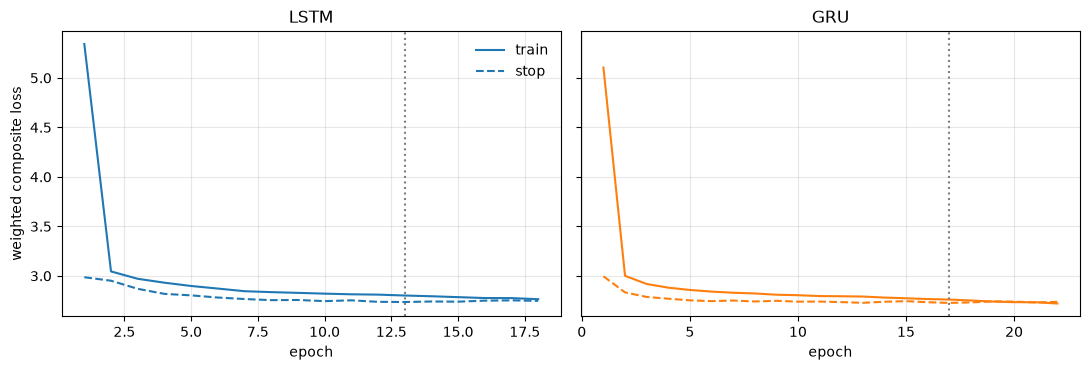

In [8]:
from src.models.trajectory_models.evaluation import MODEL_COLORS

COMPARISON_DIR.mkdir(parents=True, exist_ok=True)
fig, axes = plt.subplots(1, len(MODELS), figsize=(11, 3.8), sharey=True)
for ax, name in zip(np.atleast_1d(axes), MODELS):
    history = pd.DataFrame(best[name]["history"])
    ax.plot(history["epoch"], history["train_loss"], color=MODEL_COLORS[name], label="train")
    ax.plot(history["epoch"], history["stop_loss"], color=MODEL_COLORS[name], ls="--", label="stop")
    ax.axvline(best[name]["best_epoch"], color="grey", ls=":")
    ax.set_title(name.upper())
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)
np.atleast_1d(axes)[0].set_ylabel("weighted composite loss")
np.atleast_1d(axes)[0].legend(frameon=False)
fig.tight_layout()
fig.savefig(COMPARISON_DIR / "training_history.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Test

Each tuned architecture is refitted on all of February (`development`) for its `best_epoch`, then predicts March (days 83..89) once. A checkpoint is saved to `artifacts/sherlock_w2_v6_manual_traj/<model>/checkpoints/<model>_traj.pt`, with the parameters, the loss weights, the window sizes and the scaler phase (`development`). That is all an environment needs to reload it.

In [9]:
from src.models.trajectory_models.test import test_model

results = {}
for name in MODELS:
    print(f"\n===== {name.upper()} =====")
    results[name] = test_model(best[name], data, loss_weights=loss_weights, device=DEVICE)

preds = {name: results[name]["pred"] for name in MODELS}
TEST_ROWS = data.rows("test")
SCALER = data.states["development"]

pd.DataFrame(
    [
        {
            "model": name.upper(),
            "epochs": results[name]["epochs"],
            "parameters": results[name]["n_parameters"],
            "seconds_per_epoch": round(results[name]["seconds_per_epoch"], 2),
            "checkpoint": str(results[name].get("checkpoint", "")),
        }
        for name in MODELS
    ]
).set_index("model")


===== LSTM =====
scaled tensor for phase 'development' cached in 5.0s

===== GRU =====


,epochs,parameters,seconds_per_epoch,checkpoint
model,,,,
LSTM,13,216013,3.07,artifacts/sherlock_w2_v6_manual_traj/lstm/chec...
GRU,17,45453,1.84,artifacts/sherlock_w2_v6_manual_traj/gru/check...


## 5. Evaluation

The error alone does not say whether a model is useful, so every group is compared with a predictor that learns nothing. All numbers are in the raw encoding: listening in `log1p`, amounts in NTD and days.

| Group | Metric | Baselines |
|---|---|---|
| Listening (0–6) | MAE, RMSE, skill = 1 − MAE / MAE(persistence) | persistence (day 82), mean of days 76–82, previous week |
| `active` | AUC, AP, Brier | active on day 82, active share of days 76–82 |
| `pay` (daily and weekly) | AUC, AP, Brier | expiry rule: a customer with a known, non-cancelled membership pays on its expiry day (`exp(-|days_to_expire - h|)`) |
| Amount and plan | MAE on real payment days | last amount paid |

The model's point forecast for listening is `p(active) × amount if active`.

In [10]:
from src.models.trajectory_models.evaluation import evaluate_trajectories

report = evaluate_trajectories(preds, data, TEST_ROWS, scaler_state=SCALER)
for key in ("listening", "horizon", "channel", "events", "amounts"):
    report[key].to_csv(COMPARISON_DIR / f"{key}.csv")

print("Listening (log1p)")
display(report["listening"].round(4))
print("Events")
display(report["events"].round(4))
print("Paid amount and plan days on real payment days")
display(report["amounts"].round(3))

Listening (log1p)


,MAE,RMSE,skill_vs_persistence,MAE_active_days,MAE_inactive_days,MAE_users_with_logs
predictor,,,,,,
LSTM,1.0313,1.5882,0.0306,1.0442,1.0059,1.0359
GRU,1.0191,1.5753,0.0421,0.9800,1.0963,1.0208
persistence,1.0639,2.0391,0.0000,1.1355,0.9226,1.0772
mean_7d,0.9864,1.6984,0.0729,1.0040,0.9516,0.9969
previous_week,1.1087,2.1077,-0.0421,1.1929,0.9423,1.1236


Events


prevalence     AUC      AP   Brier  mean_predicted
target   predictor                                                      
active   LSTM             0.6638  0.8048  0.8864  0.1701          0.5969
         GRU              0.6638  0.8043  0.8861  0.1662          0.6373
         persistence      0.6638  0.6845  0.7617     NaN             NaN
         mean_7d          0.6638  0.7688  0.8390     NaN             NaN
pay      LSTM             0.0246  0.8887  0.1815  0.0222          0.0269
         GRU              0.0246  0.9024  0.1791  0.0226          0.0277
         expiry_rule      0.0246  0.7004  0.1117     NaN             NaN
pay_week LSTM             0.1703  0.9776  0.8987  0.0419          0.1335
         GRU              0.1703  0.9792  0.8971  0.0397          0.1340
         expiry_rule      0.1703  0.7237  0.5902     NaN             NaN

Paid amount and plan days on real payment days


,n_payment_days,MAE_paid_NTD,MAE_plan_days
predictor,,,
LSTM,19593,58.994,8.829
GRU,19593,56.720,9.143
last_paid,19593,32.540,7.643


**Which single number to report.** The expected value `p(active) × amount` minimises the squared error (RMSE). Under the absolute error (MAE) the best single number is the median: on a listen-or-not day that is the predicted amount when `p(active) > 0.5` and 0 otherwise. The table compares both point forecasts of the same models with the 7-day mean.

In [ ]:
from src.models.trajectory_models.evaluation import listening_point_forecasts

point_forecasts = listening_point_forecasts(preds, data, TEST_ROWS, scaler_state=SCALER)
point_forecasts.to_csv(COMPARISON_DIR / "listening_point_forecasts.csv")
point_forecasts.sort_values("MAE").round(4)

In [16]:
# Median and spread of the listening error (log1p units), next to the means of the table above.
# The MAE averages very different cells (channels, active vs silent days, stable vs changing
# users); the median says what a typical error looks like.
from src.models.trajectory_models.config import LISTEN_AMOUNT_CHANNELS
from src.models.trajectory_models.decode import expected_listening
from src.models.trajectory_models.evaluation import _listen_baselines

n_listen = len(LISTEN_AMOUNT_CHANNELS)
predictors = [name.upper() for name in preds] + ["persistence", "mean_7d", "previous_week"]
abs_err = {key: [] for key in predictors}          # (users, 7 days, 7 channels) per predictor
active_days = []

rows = np.asarray(TEST_ROWS)
for start in range(0, len(rows), 20_000):
    pos = slice(start, min(start + 20_000, len(rows)))
    raw = data.raw(rows[pos])
    real = raw[:, INPUT_DAYS:, :n_listen]
    active_days.append(raw[:, INPUT_DAYS:, data.index["active"]] > 0)
    for name in preds:
        block = {k: v[pos] for k, v in preds[name].items()}
        abs_err[name.upper()].append(np.abs(expected_listening(block, SCALER) - real).astype(np.float32))
    for key, forecast in _listen_baselines(raw).items():
        abs_err[key].append(np.abs(forecast - real).astype(np.float32))

abs_err = {k: np.concatenate(v) for k, v in abs_err.items()}
active_days = np.concatenate(active_days)

# 1. Every (user, day, channel) error: mean vs median, overall and on active / silent days.
summary = pd.DataFrame({
    key: {
        "mean": err.mean(),
        "median": np.median(err),
        "p75": np.quantile(err, 0.75),
        "p90": np.quantile(err, 0.90),
        "median, active days": np.median(err[active_days]),
        "median, silent days": np.median(err[~active_days]),
    }
    for key, err in abs_err.items()
}).T
print("Listening error per (user, day, channel), log1p units")
display(summary.round(3))

# 2. Median per channel (total_secs dominates the mean).
print("Median error per channel")
display(pd.DataFrame({key: np.median(err, axis=(0, 1)) for key, err in abs_err.items()},
                     index=list(LISTEN_AMOUNT_CHANNELS)).T.round(3))

# 3. Per user: their mean error over the 7 days x 7 channels, and how it is distributed.
per_user = {key: err.mean(axis=(1, 2)) for key, err in abs_err.items()}
print("Per-user error (mean of each user's 7 x 7 cells)")
display(pd.DataFrame({
    key: {"median user": np.median(u), "p25": np.quantile(u, 0.25), "p75": np.quantile(u, 0.75),
          "share < 0.5": (u < 0.5).mean(), "share > 2": (u > 2).mean()}
    for key, u in per_user.items()
}).T.round(3))

Listening error per (user, day, channel), log1p units


,mean,median,p75,p90,"median, active days","median, silent days"
LSTM,1.031,0.584,1.353,2.496,0.654,0.416
GRU,1.019,0.585,1.317,2.401,0.623,0.481
persistence,1.064,0.566,1.352,2.709,0.693,0.000
mean_7d,0.986,0.530,1.203,2.398,0.613,0.297
previous_week,1.109,0.629,1.387,2.834,0.693,0.000


Median error per channel


,num_25,num_50,num_75,num_985,num_100,num_unq,total_secs
LSTM,0.592,0.315,0.252,0.269,1.025,1.057,2.801
GRU,0.619,0.331,0.264,0.285,1.003,1.031,2.595
persistence,0.693,0.154,0.000,0.000,0.764,0.773,0.922
mean_7d,0.594,0.338,0.256,0.265,0.859,0.877,1.927
previous_week,0.693,0.183,0.000,0.000,0.828,0.847,1.008


Per-user error (mean of each user's 7 x 7 cells)


,median user,p25,p75,share < 0.5,share > 2
LSTM,1.037,0.833,1.233,0.049,0.004
GRU,1.022,0.806,1.224,0.043,0.004
persistence,1.000,0.673,1.396,0.144,0.073
mean_7d,0.985,0.689,1.255,0.119,0.020
previous_week,1.082,0.765,1.431,0.100,0.049


### 5.1 Error by horizon and by channel

The error should grow with h. A flat curve means the model is predicting something close to a constant.

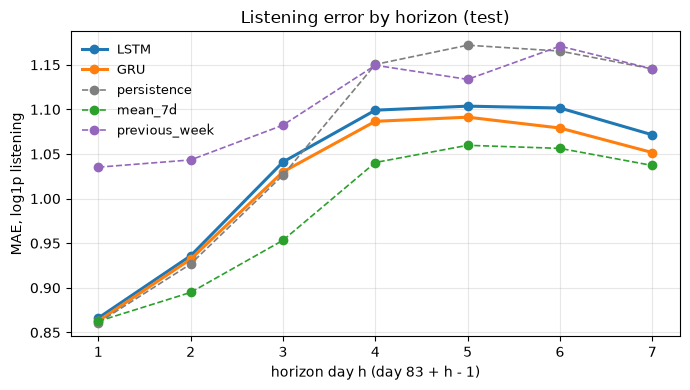

,h1,h2,h3,h4,h5,h6,h7
LSTM,0.8662,0.9359,1.0411,1.0992,1.1037,1.1016,1.0715
GRU,0.8629,0.9322,1.0300,1.0867,1.0913,1.0791,1.0517
persistence,0.8610,0.9267,1.0263,1.1504,1.1720,1.1654,1.1455
mean_7d,0.8625,0.8949,0.9533,1.0405,1.0598,1.0563,1.0372
previous_week,1.0353,1.0434,1.0824,1.1495,1.1337,1.1709,1.1455


,num_25,num_50,num_75,num_985,num_100,num_unq,total_secs
LSTM,0.7638,0.4539,0.3682,0.3829,1.1310,1.1525,2.9670
GRU,0.7735,0.4597,0.3723,0.3894,1.1213,1.1425,2.8753
persistence,0.8778,0.5164,0.4097,0.4177,1.2001,1.2261,2.7993
mean_7d,0.7687,0.4606,0.3718,0.3805,1.0904,1.1128,2.7194
previous_week,0.9002,0.5249,0.4155,0.4244,1.2515,1.2802,2.9634


In [11]:
from src.models.trajectory_models.evaluation import plot_horizon

plot_horizon(report, save_path=COMPARISON_DIR / "horizon_mae.png")
plt.show()
display(report["horizon"].round(4))
display(report["channel"].round(4))

### 5.2 Example trajectories

Real `total_secs` (last 4 weeks of input + the 7 target days) against each model's expected forecast, for active users, users who fade out and inactive users.

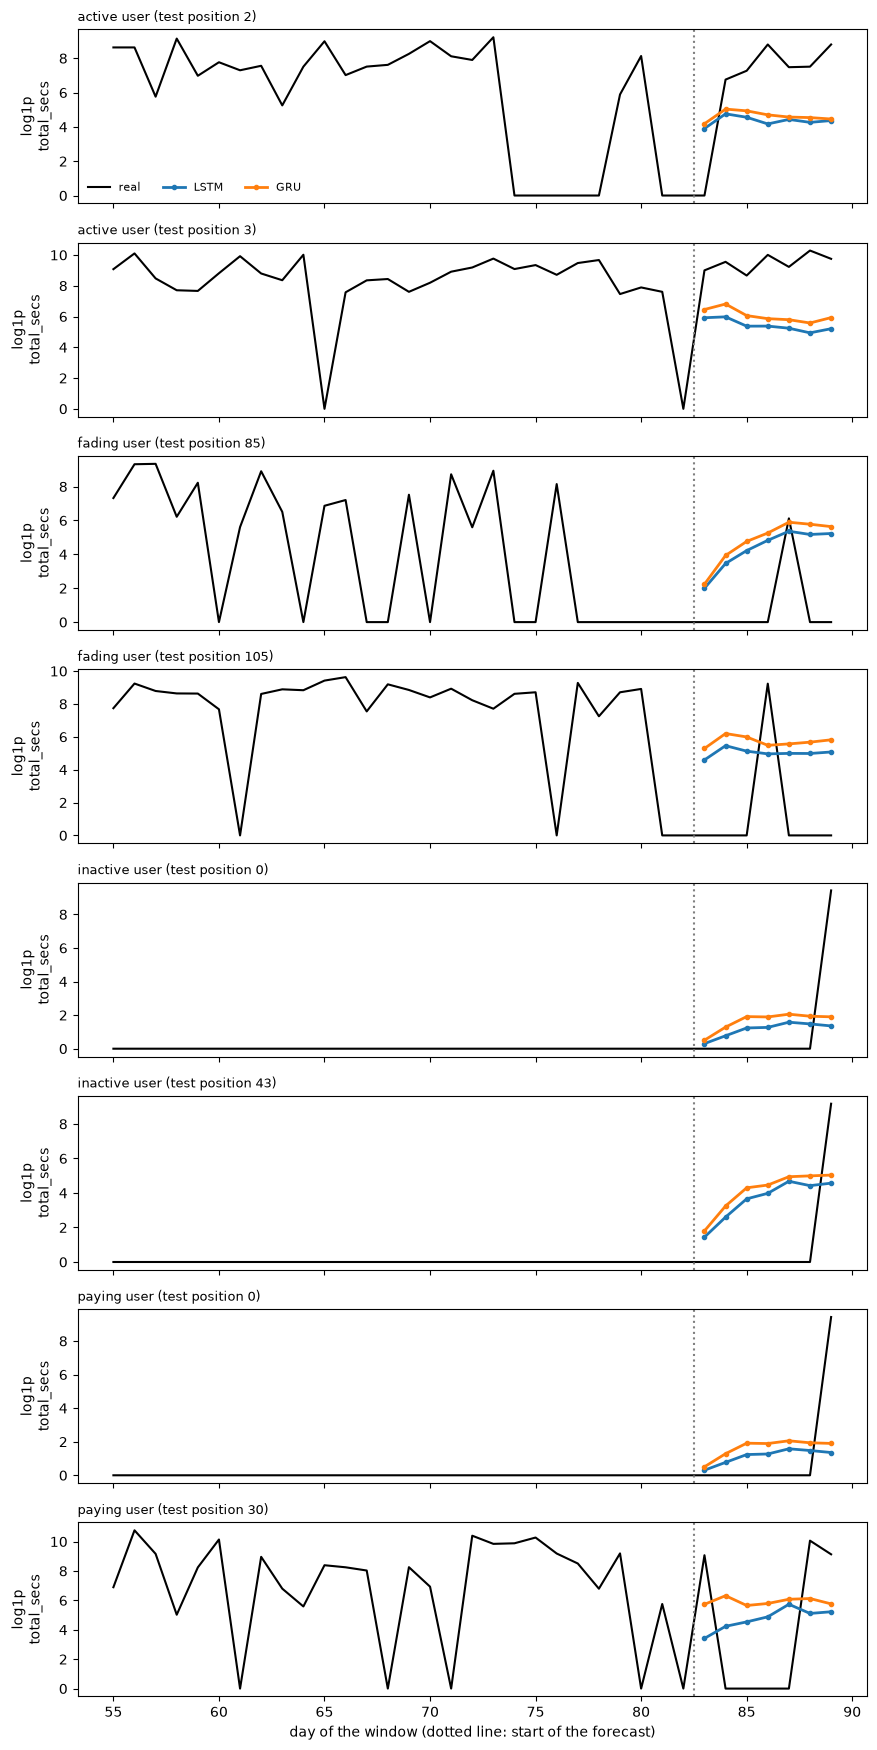

In [12]:
from src.models.trajectory_models.evaluation import pick_example_users, plot_example_trajectories

examples = pick_example_users(data, TEST_ROWS)
plot_example_trajectories(
    preds, data, TEST_ROWS, examples, scaler_state=SCALER,
    save_path=COMPARISON_DIR / "example_trajectories.png",
)
plt.show()

**Reading the listening examples.** The curve drawn for each model is the *expected* value `p(active) × amount if active`, not a sampled trajectory. A real user either listens a lot or not at all on a given day; the expectation of a 60 % chance of listening ~8 log-seconds is ~5, a value that never happens. That is why the forecasts look flat and "in the middle" on every example, and why the listening MAE barely beats `mean_7d`: under absolute error a smooth average is what any model ends up producing. The useful part of the forecast is the probability of each **event**, shown next.

### 5.3 Events: will the user listen, will the user pay?

The event heads are where the model learns something the baselines do not have (section 5 table: active AUC 0.81 vs 0.77 for `mean_7d`, weekly payment AP 0.90 vs 0.58 for the expiry rule).

1. ROC and precision-recall curves of `active`, daily `pay` and weekly `pay`, against the baselines.
2. Calibration: the simulator samples events from these probabilities, so they must match the observed frequencies.
3. Payments aligned to each user's expiry (known on day 82): real payment rate vs mean predicted `p_pay`. Manual users pay around their expiry date, so this shows whether the model learned *when* they pay.
4. The same kind of example users, now with the events: real active and payment days against `p_active` and `p_pay`.

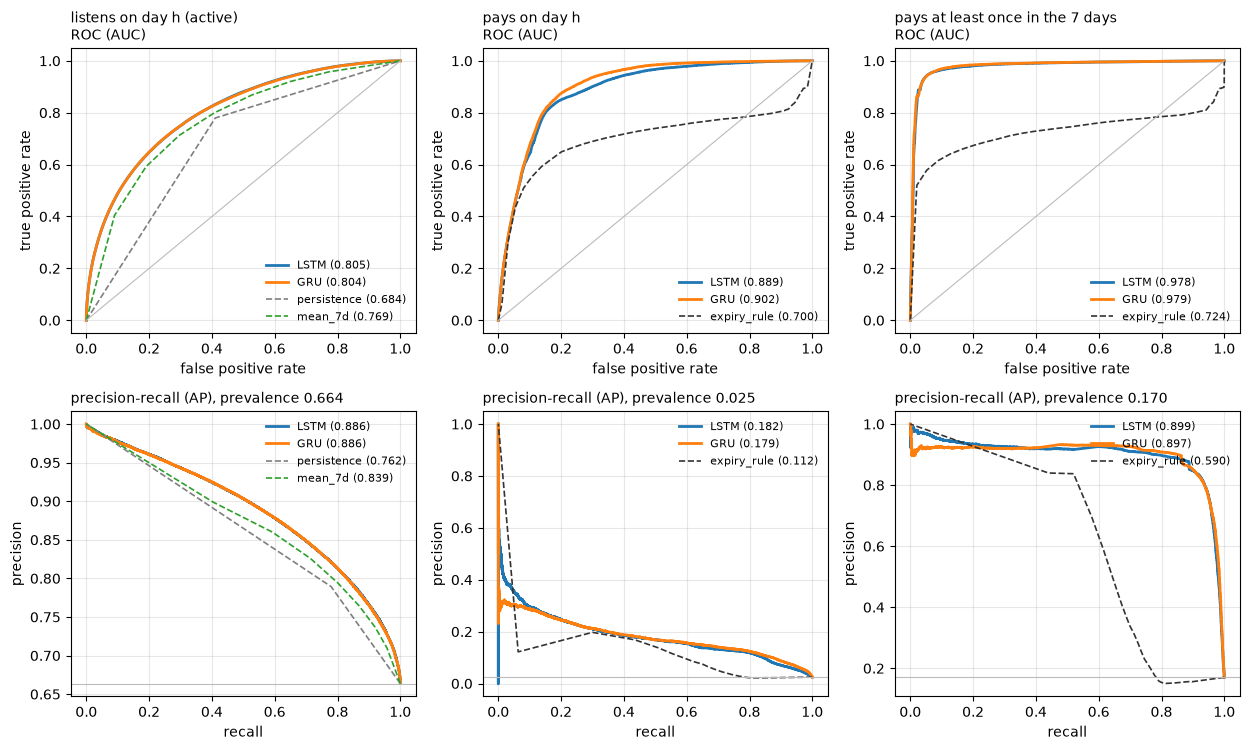

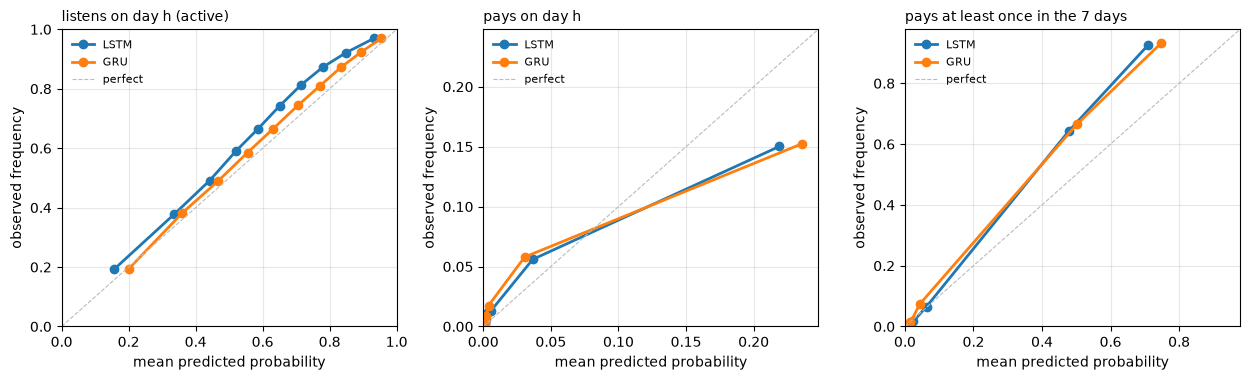

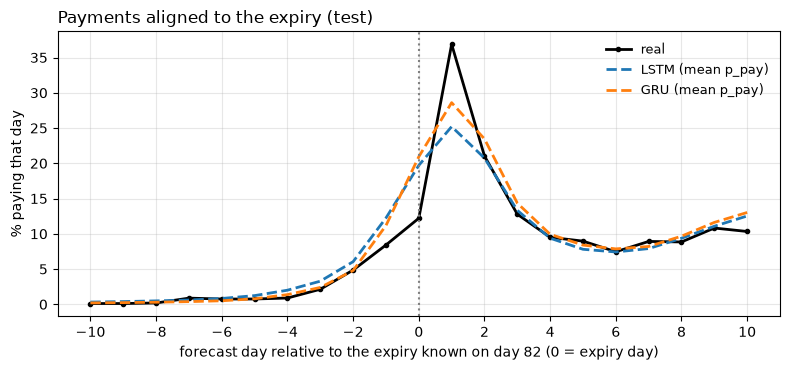

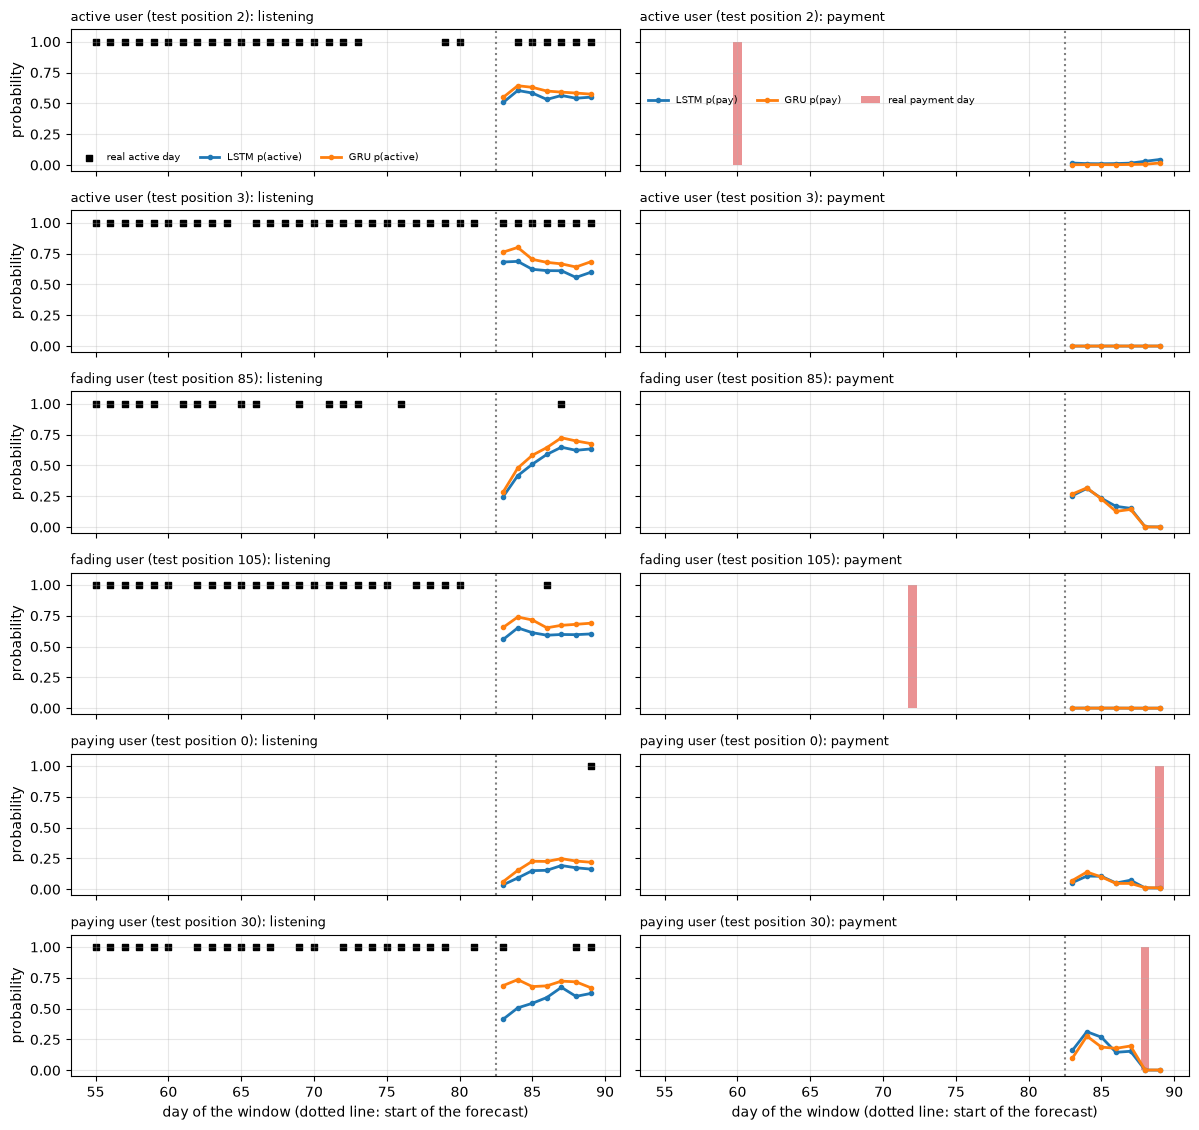

In [13]:
from src.models.trajectory_models.evaluation import (
    plot_event_calibration, plot_event_curves, plot_example_events, plot_pay_by_expiry)

plot_event_curves(report, save_path=COMPARISON_DIR / "event_curves.png")
plt.show()
plot_event_calibration(report, save_path=COMPARISON_DIR / "event_calibration.png")
plt.show()
plot_pay_by_expiry(report, save_path=COMPARISON_DIR / "pay_by_expiry.png")
plt.show()
event_examples = {g: examples[g] for g in ("active", "fading", "paying") if g in examples}
plot_example_events(preds, data, TEST_ROWS, event_examples,
                    save_path=COMPARISON_DIR / "example_events.png")
plt.show()

## 6. LSTM vs GRU

The per-user listening MAE of both models is compared with a paired bootstrap: the same resampled users score both models, so the interval of the difference accounts for their correlation. If the interval contains 0, the smaller and faster model is preferable.

In [14]:
from src.models.trajectory_models.evaluation import paired_bootstrap_mean

names = list(MODELS)
boot = paired_bootstrap_mean(
    report["per_user_listen_mae"][names[0]],
    report["per_user_listen_mae"][names[1]],
    n_boot=1000,
    seed=SEED,
)
print(f"Per-user listening MAE, difference = {names[0].upper()} - {names[1].upper()}")
display(pd.Series(boot).to_frame("value"))

summary = pd.DataFrame(
    {
        name.upper(): {
            "listening MAE": report["listening"].loc[name.upper(), "MAE"],
            "skill vs persistence": report["listening"].loc[name.upper(), "skill_vs_persistence"],
            "active AUC": report["events"].loc[("active", name.upper()), "AUC"],
            "pay AP": report["events"].loc[("pay", name.upper()), "AP"],
            "weekly pay AP": report["events"].loc[("pay_week", name.upper()), "AP"],
            "parameters": results[name]["n_parameters"],
            "seconds/epoch": results[name]["seconds_per_epoch"],
        }
        for name in names
    }
)
summary.to_csv(COMPARISON_DIR / "summary.csv")
summary

Per-user listening MAE, difference = LSTM - GRU


,value
mean_a,1.031312
mean_b,1.01912
diff,0.012191
ci_low,0.011673
ci_high,0.012677
significant,True


,LSTM,GRU
listening MAE,1.031312,1.019120
skill vs persistence,0.030634,0.042093
active AUC,0.804780,0.804303
pay AP,0.181524,0.179077
weekly pay AP,0.898680,0.897150
parameters,216013.000000,45453.000000
seconds/epoch,3.071861,1.837857


## 7. Artifacts and limitations

```text
artifacts/sherlock_w2_v6_manual_traj/
├── loss_weights.json             # fixed loss weights (shared by both models)
├── lstm/ , gru/
│   ├── optuna/                   # study, trials, best params, best-trial history
│   └── checkpoints/<model>_traj.pt
└── comparison/                   # tables (csv) and figures
```

Limitations:

- **Not comparable with the classifier.** The classifier predicts churn (log-loss, AUC); this notebook predicts trajectories (MAE, AUC of daily events). They are different tasks.
- **No simulator.** The state channels are not rebuilt and no week is sampled; only the predicted events are evaluated.
- **No response to offers.** The training data contain no retention actions.
- **Shifted use.** Training uses days 83..89 of the window. In an environment the model is applied to the last 83 days before the cutoff. It has no calendar input, so this works, but it assumes behaviour is stable over time.